In [2]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data.labels import load_labels
from src.analysis.class_distribution import analyze_class_distribution
from src.analysis.class_distribution import recommend_class_weighting

import matplotlib.pyplot as plt 

NEW LABELS.PY LOADED


In [3]:
csv_path = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv"
)

labels, _ = load_labels(csv_path)

In [4]:
class_df = analyze_class_distribution(labels)

class_df

,Class,Count,Percentage
0,Positive,6012,22.53
1,Negative,20672,77.47


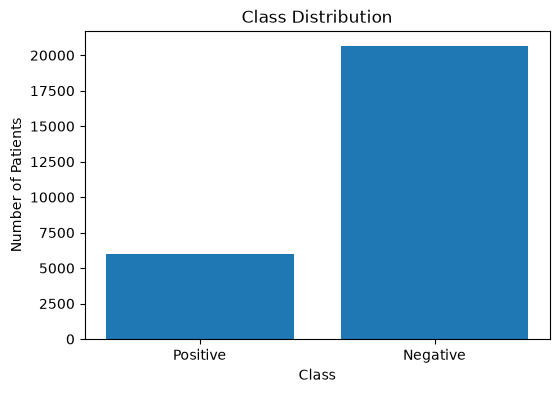

In [5]:
#Bar chart

plt.figure(figsize=(6,4))

plt.bar(
    class_df["Class"],
    class_df["Count"]
)

plt.title("Class Distribution")

plt.xlabel("Class")

plt.ylabel("Number of Patients")

plt.show()

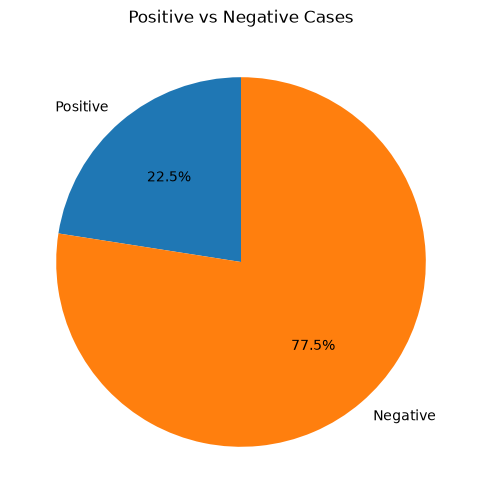

In [6]:
# Pie chart

plt.figure(figsize=(6,6))

plt.pie(
    class_df["Count"],
    labels=class_df["Class"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Positive vs Negative Cases")

plt.show()

In [7]:
print(recommend_class_weighting(class_df))

Class imbalance detected. Consider weighted loss or focal loss.


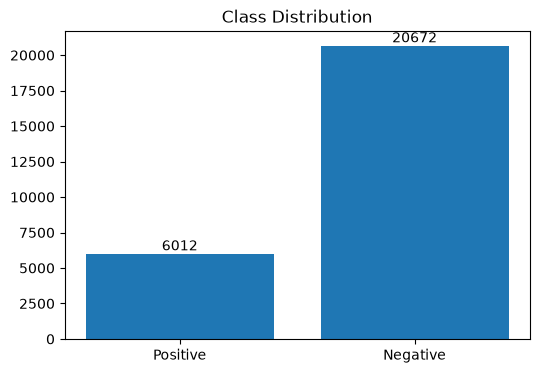

In [8]:
# Count Labels

plt.figure(figsize=(6,4))

bars = plt.bar(
    class_df["Class"],
    class_df["Count"]
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.title("Class Distribution")

plt.show()